# Saved Improved MLP: hour ablation and joint pair representations

Load the existing best Improved MLP, plot its final hidden Linear representation before ReLU, then compare with one same-seed retrained model without hour sine/cosine. One point is one complete user–candidate pair, including all inputs used by the ranker. There is one joint hidden representation per model, not separate article/category spaces.

For each model, show the same PCA points twice: two blue shades for observed clicked/unclicked labels, then a continuous blue palette for predicted raw ranking scores. Add a blue score-density histogram and a score-distribution table. Keep the validation/test hourly comparisons.

No additional training is required when the existing without-hour checkpoint is present. Do not rerun preprocessing or the comprehensive ablation notebook. Missing reference weights stop execution instead of triggering reference training.


## 1. Colab: refactor-final, new outputs in run_02


In [2]:
# Configure this cell before running on Google Colab.
import os
import sys
import subprocess
from pathlib import Path

try:
    from google.colab import drive
except ImportError:
    drive = None

if drive is not None:
    REPO_URL = "https://github.com/nguyenvanminh281005/bt4222-group12.git"
    BRANCH = "refactor-final"
    RUN_NAME = "run_02"
    BASE = Path("/content/drive/MyDrive/BT4222 - Group 12")
    CHECKOUT = Path("/content/bt4222_checkout")
    drive.mount("/content/drive")
    if not CHECKOUT.exists():
        subprocess.run([
            "git", "clone", "--branch", BRANCH, "--single-branch",
            REPO_URL, str(CHECKOUT)
        ], check=True)
    active_branch = subprocess.check_output(
        ["git", "-C", str(CHECKOUT), "branch", "--show-current"], text=True
    ).strip()
    if active_branch != BRANCH:
        raise ValueError("Checkout branch differs from BRANCH. Use a fresh Colab runtime.")
    CODE_DIR = (CHECKOUT if (CHECKOUT / "utils/data_utils.py").is_file()
                else CHECKOUT / "bt4222-group12")
    if not (CODE_DIR / "utils/data_utils.py").is_file():
        raise FileNotFoundError("The selected branch does not contain the Group 12 project.")
    os.environ.update({
        "BT4222_BASE": str(BASE),
        "MIND_DATA_DIR": str(BASE / "data"),
        "BT4222_PROCESSED_DIR": str(BASE / "processed"),
        "BT4222_FEATURE_DIR": str(BASE / "features"),
        "BT4222_GLOVE_PATH": str(BASE / "data/glove/glove.6B.300d.txt"),
        "BT4222_OUTPUT_DIR": str(BASE / "runs" / RUN_NAME),
    })
    os.chdir(CODE_DIR)
    subprocess.run([
        sys.executable, "-m", "pip", "install", "-r", "requirements.txt"
    ], check=True)
    print("Code:", CODE_DIR)
    print("Features:", os.environ["BT4222_FEATURE_DIR"])
    print("Run outputs:", os.environ["BT4222_OUTPUT_DIR"])


Mounted at /content/drive
Code: /content/bt4222_checkout
Features: /content/drive/MyDrive/BT4222 - Group 12/features
Run outputs: /content/drive/MyDrive/BT4222 - Group 12/runs/run_02


In [3]:
import os
import sys
from pathlib import Path

PROJECT_ROOT = next(
    p
    for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "utils" / "data_utils.py").is_file()
)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from utils.data_utils import project_paths, load_preprocessed, load_table, save_table

if os.environ.get("BT4222_USE_DRIVE") == "1":
    from google.colab import drive

    drive.mount("/content/drive")

PATHS = project_paths(PROJECT_ROOT)
from utils.data_utils import source_fingerprint, validate_features, bind_feature_run

feature_id = validate_features(PATHS)
bind_feature_run(PATHS, feature_id)


In [4]:
from utils.metrics import ndcg_at_k, history_groups


In [5]:
import os, json, time, copy, random, hashlib
import numpy as np
import pandas as pd
from scipy.stats import rankdata
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as Fnn
from torch.utils.data import DataLoader
from sklearn.decomposition import PCA
from IPython.display import display

device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
FEATURE_DIR=str(PATHS["features"])
OUT_DIR=Path(PATHS["outputs"])/"mlp"/"saved_best_hour_ablation"
OUT_DIR.mkdir(parents=True,exist_ok=True)
FIG_DIR=OUT_DIR/"figures"
FIG_DIR.mkdir(exist_ok=True)
# The supplied executed notebook wrote its best model under run_01.
REFERENCE_RUN_NAME="run_01"
REFERENCE_DIR=Path(PATHS["outputs"]).parent/REFERENCE_RUN_NAME/"mlp"/"staged"/"stage4_final"
REFERENCE_WEIGHTS=REFERENCE_DIR/"final_model.pt"
REFERENCE_CONFIG=REFERENCE_DIR/"run_config.json"
LATENT_IMPRESSIONS=500
BOOTSTRAP_REPEATS=1000
SPLITS=["train","val","test"]
NDCG_KS=RECALL_KS=(5,10)
EVAL_BATCH=128
def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR/name,dpi=180,bbox_inches="tight")
    plt.show()
def load_feature_table(name):
    p=Path(FEATURE_DIR)/name
    return pd.read_parquet(str(p)+".parquet") if Path(str(p)+".parquet").exists() else pd.read_pickle(str(p)+".pkl")
print("Reference weights:",REFERENCE_WEIGHTS)
print("New outputs:",OUT_DIR)


Reference weights: /content/drive/MyDrive/BT4222 - Group 12/runs/run_01/mlp/staged/stage4_final/final_model.pt
New outputs: /content/drive/MyDrive/BT4222 - Group 12/runs/run_02/mlp/saved_best_hour_ablation


## 2. Read the saved configuration before loading weights
The supplied notebook saved both `staged/stage2_improved/improved_mlp_best.pt` and `staged/stage4_final/final_model.pt`. Use the final export with its `run_config.json`, which records selected features, hyperparameters, seed and feature identity. These files are on Drive; the `.ipynb` does not contain its model weights.

This focused study expects the saved final model to be **Improved MLP**, as in the supplied output. If you select a different reference run, verify its final model/config first. Raw ranker scores are compared consistently; any optional cold-user popularity fallback is recorded but not applied to either model.


In [6]:
for p in (REFERENCE_WEIGHTS,REFERENCE_CONFIG):
    if not p.is_file():
        raise FileNotFoundError(f"Saved reference missing: {p}. Set REFERENCE_DIR to the existing stage4_final export; reference training is disabled.")
reference_config=json.loads(REFERENCE_CONFIG.read_text())
if reference_config["final_model"]!="Improved MLP":
    raise ValueError("This notebook expects the saved Improved MLP selected in the supplied notebook.")
hp=reference_config["hyperparameters"]
if hp["feature_id"]!=feature_id:
    raise ValueError("The saved checkpoint and current feature bundle have different identities; use the original bundle.")
SEED=int(hp["seed"])
EMBED_DIM=int(hp["embed_dim"])
CAT_DIM=int(hp["cat_dim"])
SUBCAT_DIM=int(hp["subcat_dim"])
HIDDEN=list(hp["hidden"])
DROPOUT=float(hp["dropout"])
ID_DROPOUT=float(hp["id_dropout"])
LR=float(hp["lr"])
WEIGHT_DECAY=float(hp["weight_decay"])
BATCH_SIZE=int(hp["batch_size"])
MAX_EPOCHS=int(hp["epochs"])
PATIENCE=int(hp["patience"])
SELECT_METRIC=hp["select_metric"]
COLD_SIM_RATE=float(reference_config["cold_user_simulation"]["rate"])
USE_GROUPS=dict(article=True,popularity=True,user=True,user_x_article=True,context=True)
USE_OPTIONAL={name:name not in reference_config["dropped_features"] for name in ("diversity_ratio","habit_score")}
print("Reference model:",reference_config["final_model"],"seed:",SEED,"learning rate:",LR)
print("Dropped features:",reference_config["dropped_features"])
print("Reference cold-user fallback (not applied in this comparison):",reference_config["cold_user_fallback"])


Reference model: Improved MLP seed: 42 learning rate: 0.001
Dropped features: ['diversity_ratio', 'habit_score']
Reference cold-user fallback (not applied in this comparison): False


## 3. Load the original prepared inputs and exact architecture


In [7]:
with open(os.path.join(FEATURE_DIR, "feature_meta.json")) as f:
    meta = json.load(f)

dims = meta["dims"]
N_ART, N_CAT, N_SUBCAT = dims["n_articles"], dims["n_cat"], dims["n_subcat"]
SPARSE_MAX = meta["cold_start"]["sparse_user_max"]
articles = load_feature_table("articles")
content_emb = np.load(os.path.join(FEATURE_DIR, "article_content_emb.npy")).astype(
    np.float32
)
kg_emb = np.load(os.path.join(FEATURE_DIR, "kg_entity_emb.npy")).astype(np.float32)
has_kg = np.zeros(N_ART, np.float32)
has_kg[articles.news_idx.values] = articles.has_kg_entity.values
art_cat = np.zeros(N_ART, np.int64)
art_cat[articles.news_idx.values] = articles.category_idx.values
art_subcat = np.zeros(N_ART, np.int64)
art_subcat[articles.news_idx.values] = articles.subcategory_idx.values
news_ids = np.empty(N_ART, dtype=object)
news_ids[0] = "<PAD>"
news_ids[articles.news_idx.values] = articles.news_id.values
profiles = (
    load_feature_table("user_profiles").sort_values("profile_idx").reset_index(drop=True)
)
user_emb = np.load(os.path.join(FEATURE_DIR, "user_history_emb.npy")).astype(np.float32)
user_aff = np.load(os.path.join(FEATURE_DIR, "user_category_affinity.npy")).astype(
    np.float32
)
data = {
    s: {
        "imp": load_feature_table(f"{s}/impressions"),
        "groups": load_feature_table(f"{s}/groups"),
        "cands": load_feature_table(f"{s}/candidates"),
    }
    for s in SPLITS
}

for s in SPLITS:
    print(
        f"{s:5s}: {len(data[s]['groups']):>8,} groups | {len(data[s]['cands']):>10,} candidates | "
        f"days {[int(x) for x in sorted(data[s]['imp'].day.unique())]}"
    )

print(
    "Split:",
    meta["split"]["scheme"],
    "| negatives:",
    meta["negative_sampling"]["train"],
)


train:  189,519 groups |    906,625 candidates | days [0, 1, 2, 3, 4]
val  :   30,270 groups |  1,222,429 candidates | days [5]
test :   73,152 groups |  2,740,998 candidates | days [6]
Split: 5-1-1 by calendar day | negatives: per positive, up to 4 negatives from same impression, no replacement, seed 42; short groups masked (no repeats); impressions without negatives dropped


In [8]:
prepared_inputs = pd.read_pickle(Path(FEATURE_DIR) / "mlp_inputs.pkl")
A = prepared_inputs["A"]
cand_mu, cand_sd = prepared_inputs["cand_mu"], prepared_inputs["cand_sd"]
user_mu, user_sd = prepared_inputs["user_mu"], prepared_inputs["user_sd"]
ctx_mu, ctx_sd = prepared_inputs["ctx_mu"], prepared_inputs["ctx_sd"]
user_x_all = prepared_inputs["user_x_all"]

F = meta["features"]
POP_COLS = F["popularity"]  # hist_ctr, log_exposure, is_cold_article
INTER_COLS = F["user_x_article"]  # 6 user x article features
CAND_COLS = POP_COLS + INTER_COLS
OPTIONAL_USER = F["optional"]["user"]  # diversity_ratio
OPTIONAL_CTX = F["optional"]["context"]  # habit_score
USER_COLS = F["user"]["scalar"] + OPTIONAL_USER  # all user scalars stored in user_x
CTX_COLS = F["context"] + OPTIONAL_CTX  # all context features stored in ctx_x
OPTIONAL_FEATURES = OPTIONAL_USER + OPTIONAL_CTX
BINARY = {"is_cold_article", "category_match", "has_history"}
CTR_COL = CAND_COLS.index("hist_ctr")
used = set(CAND_COLS + USER_COLS + CTX_COLS) | {
    "article_content_emb",
    "kg_entity_emb",
    "category_idx",
    "subcategory_idx",
}
assert not used & set(meta["excluded_features"]), "contract: excluded feature in use"


def make_config(name, groups=None, drop=()):
    """A model config = which groups are on + which individual features are dropped."""
    return {
        "name": name,
        "groups": dict(groups or USE_GROUPS),
        "drop": sorted(set(drop)),
    }


def active_features(cfg):
    """Feature names actually fed to the model under cfg, per input block."""
    keep = lambda cols: [c for c in cols if c not in cfg["drop"]]
    g = cfg["groups"]
    return {
        "popularity": keep(POP_COLS) if g["popularity"] else [],
        "user_x_article": keep(INTER_COLS) if g["user_x_article"] else [],
        "user": keep(USER_COLS) if g["user"] else [],
        "context": keep(CTX_COLS) if g["context"] else [],
    }


FULL_CFG = make_config(
    "full", USE_GROUPS, drop=[f for f in OPTIONAL_FEATURES if not USE_OPTIONAL.get(f)]
)

for block, cols in active_features(FULL_CFG).items():
    print(f"{block:15s}: {cols}")

assert A["train"]["n"].max() <= 5

for s in SPLITS:
    hl = A[s]["hist_len"]
    print(
        f"{s:5s}: cold users {np.mean(hl == 0):.2%} | sparse (1-{SPARSE_MAX-1}) {np.mean((hl > 0) & (hl < SPARSE_MAX)):.2%} "
        f"| cold-article candidates {A[s]['is_cold_article'].mean():.2%}"
    )


popularity     : ['hist_ctr', 'log_exposure', 'is_cold_article']
user_x_article : ['category_match', 'cos_user_hist', 'max_cos_hist', 'cos_last5', 'cat_affinity', 'kg_match']
user           : ['log_history_length', 'has_history', 'reading_entropy']
context        : ['hour_sin', 'hour_cos']
train: cold users 1.91% | sparse (1-4) 9.57% | cold-article candidates 65.21%
val  : cold users 2.55% | sparse (1-4) 10.73% | cold-article candidates 60.33%
test : cold users 3.03% | sparse (1-4) 11.06% | cold-article candidates 54.86%


In [9]:
METRIC_NAMES = (
    ["AUC", "MRR"] + [f"nDCG@{k}" for k in NDCG_KS] + [f"Recall@{k}" for k in RECALL_KS]
)


def impression_metrics(labels, scores):
    order = np.argsort(-scores, kind="stable")
    y = labels[order]
    n_pos = y.sum()
    ranks = np.arange(1, len(y) + 1)
    out = {"MRR": float((y / ranks).sum() / n_pos)}
    for k in NDCG_KS:
        out[f"nDCG@{k}"] = ndcg_at_k(labels, y, k)
    for k in RECALL_KS:
        out[f"Recall@{k}"] = float(y[:k].sum() / n_pos)
    n_neg = len(y) - n_pos
    if n_neg > 0:
        r = rankdata(scores)
        out["AUC"] = float(
            (r[labels == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)
        )
    else:
        out["AUC"] = np.nan
    return out


def evaluate(Ad, scores):
    """Returns (metrics table per slice, per-impression metrics)."""
    rows, cold_rows = [], []
    for g in range(len(Ad["n"])):
        s, k = Ad["start"][g], Ad["n"][g]
        lab, sc = Ad["label"][s : s + k], scores[s : s + k]
        rows.append(impression_metrics(lab, sc))
        cold = Ad["is_cold_article"][s : s + k] == 1
        cold_pos = (lab == 1) & cold
        if cold_pos.any():
            keep = ~((lab == 1) & ~cold)
            m = impression_metrics(cold_pos[keep].astype(np.float32), sc[keep])
            m["g"] = g
            cold_rows.append(m)
    per_imp = pd.DataFrame(rows)
    hl = Ad["hist_len"]
    slices = {
        "all": np.ones(len(hl), bool),
        "cold_user": hl == 0,
        "sparse_user": (hl > 0) & (hl < SPARSE_MAX),
        "warm_user": hl >= SPARSE_MAX,
    }
    table = []
    for name, m in slices.items():
        sub = per_imp[m]
        table.append(
            {
                "slice": name,
                "n_impressions": int(m.sum()),
                "n_users": int(pd.unique(Ad["user_id"][m]).size),
                **{k: sub[k].mean() for k in METRIC_NAMES},
            }
        )
    cold_df = pd.DataFrame(cold_rows)
    n_cold_art_users = (
        int(pd.unique(Ad["user_id"][cold_df["g"].values]).size) if len(cold_df) else 0
    )
    table.append(
        {
            "slice": "cold_article",
            "n_impressions": len(cold_df),
            "n_users": n_cold_art_users,
            **{
                k: (cold_df[k].mean() if len(cold_df) else np.nan) for k in METRIC_NAMES
            },
        }
    )
    return pd.DataFrame(table), per_imp


def user_groups(Ad):
    hl = Ad["hist_len"]
    return {
        "all": np.ones(len(hl), bool),
        "warm_user": hl >= SPARSE_MAX,
        "sparse_user": (hl > 0) & (hl < SPARSE_MAX),
        "cold_user": hl == 0,
    }


def paired_bootstrap(a, b, n_boot=1000, seed=SEED):
    """Mean of a-b and its 95% interval over impressions resampled with replacement."""
    rng = np.random.default_rng(seed)
    diff = (a - b).astype(np.float64)
    boots = np.concatenate(
        [
            diff[rng.integers(0, len(diff), (100, len(diff)))].mean(1)
            for _ in range(n_boot // 100)
        ]
    )
    return diff.mean(), np.percentile(boots, 2.5), np.percentile(boots, 97.5)


# sanity check on a hand-computed example: clicked items ranked 1st and 3rd of 4
_m = impression_metrics(
    np.array([1, 0, 1, 0], np.float32), np.array([0.9, 0.8, 0.7, 0.1])
)
assert (
    abs(_m["MRR"] - (1 + 1 / 3) / 2) < 1e-9
    and abs(_m["AUC"] - 0.75) < 1e-9
    and _m["Recall@5"] == 1.0
)
assert abs(_m["nDCG@5"] - (1 + 1 / np.log2(4)) / (1 + 1 / np.log2(3))) < 1e-9
print("Metric definitions verified on a hand-computed example.")


Metric definitions verified on a hand-computed example.


In [10]:
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


class Proj(nn.Module):
    """Linear layer + LayerNorm: turns one input group into a 64-number block."""

    def __init__(self, d_in, d_out):
        super().__init__()
        self.lin, self.ln = nn.Linear(d_in, d_out), nn.LayerNorm(d_out)

    def forward(self, x):
        return self.ln(self.lin(x))


def make_head(d_in):
    """The scoring MLP: d_in -> 128 -> 64 -> 32 -> 1 score."""
    layers = []
    for h in HIDDEN:
        layers += [nn.Linear(d_in, h), nn.ReLU(), nn.Dropout(DROPOUT)]
        d_in = h
    layers.append(nn.Linear(d_in, 1))
    return nn.Sequential(*layers)


class MLPRanker(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        g, act = cfg["groups"], active_features(cfg)
        for name, arr in {
            "content_emb": content_emb,
            "kg_emb": kg_emb,
            "has_kg": has_kg,
            "art_cat": art_cat,
            "art_subcat": art_subcat,
            "user_emb": user_emb,
            "user_aff": user_aff,
        }.items():
            self.register_buffer(name, torch.as_tensor(arr), persistent=False)
        # column indices of the active features inside cand_x / user_x / ctx_x
        idx = {
            "pop_idx": [CAND_COLS.index(c) for c in act["popularity"]],
            "inter_idx": [CAND_COLS.index(c) for c in act["user_x_article"]],
            "user_idx": [USER_COLS.index(c) for c in act["user"]],
            "ctx_idx": [CTX_COLS.index(c) for c in act["context"]],
        }
        for name, cols in idx.items():
            self.register_buffer(
                name, torch.as_tensor(cols, dtype=torch.long), persistent=False
            )
        self.on = {
            "article": g["article"],
            "popularity": len(idx["pop_idx"]) > 0,
            "user_x_article": len(idx["inter_idx"]) > 0,
            "user": g["user"],
            "user_scalar": len(idx["user_idx"]) > 0,
            "context": len(idx["ctx_idx"]) > 0,
        }
        d = EMBED_DIM
        self.cat_emb = nn.Embedding(N_CAT, CAT_DIM, padding_idx=0)  # shared by article & user side
        n_blocks = 0
        if self.on["article"]:
            self.subcat_emb = nn.Embedding(N_SUBCAT, SUBCAT_DIM, padding_idx=0)
            self.text_proj = Proj(content_emb.shape[1], d)
            self.kg_proj = Proj(kg_emb.shape[1] + 1, d)
            self.cat_proj = Proj(CAT_DIM + SUBCAT_DIM, d)
            n_blocks += 3
        if self.on["popularity"]:
            self.pop_proj = Proj(len(idx["pop_idx"]), d)
            n_blocks += 1
        if self.on["user"]:
            self.user_text_proj = Proj(user_emb.shape[1], d)
            self.user_cat_proj = Proj(CAT_DIM, d)
            n_blocks += 2
            if self.on["user_scalar"]:
                self.user_num_proj = Proj(len(idx["user_idx"]), d)
                n_blocks += 1
        if self.on["user_x_article"]:
            self.inter_proj = Proj(len(idx["inter_idx"]), d)
            n_blocks += 1
        if self.on["context"]:
            self.ctx_proj = Proj(len(idx["ctx_idx"]), d)
            n_blocks += 1
        assert n_blocks > 0, "config switches every input off"
        self.n_blocks = n_blocks
        self.mlp = make_head(n_blocks * d)

    def _id_dropout(self, idx):
        if self.training and ID_DROPOUT > 0:
            drop = (torch.rand(idx.shape, device=idx.device) < ID_DROPOUT) & (idx > 1)
            idx = idx.masked_fill(drop, 1)  # 1 = <UNK>
        return idx

    def blocks(self, news, cand_x, prof, user_x, ctx_x):
        """All projected 64-d input blocks, by name, in a fixed order."""
        L = news.shape[1]
        per_user = lambda t: t.unsqueeze(1).expand(-1, L, -1)  # same user block for every candidate
        b = {}
        if self.on["article"]:
            b["text"] = self.text_proj(self.content_emb[news])
            b["kg"] = self.kg_proj(
                torch.cat([self.kg_emb[news], self.has_kg[news].unsqueeze(-1)], -1)
            )
            cat, sub = self._id_dropout(self.art_cat[news]), self._id_dropout(
                self.art_subcat[news]
            )
            b["cat"] = self.cat_proj(
                torch.cat([self.cat_emb(cat), self.subcat_emb(sub)], -1)
            )
        if self.on["popularity"]:
            b["pop"] = self.pop_proj(cand_x.index_select(-1, self.pop_idx))
        if self.on["user_x_article"]:
            b["inter"] = self.inter_proj(cand_x.index_select(-1, self.inter_idx))
        if self.on["user"]:
            b["user_text"] = per_user(self.user_text_proj(self.user_emb[prof]))
            b["user_cat"] = per_user(
                self.user_cat_proj(self.user_aff[prof] @ self.cat_emb.weight)
            )
            if self.on["user_scalar"]:
                b["user_num"] = per_user(
                    self.user_num_proj(user_x.index_select(-1, self.user_idx))
                )
        if self.on["context"]:
            b["ctx"] = per_user(self.ctx_proj(ctx_x.index_select(-1, self.ctx_idx)))
        return b

    def forward(self, news, mask, cand_x, prof, user_x, ctx_x):
        b = self.blocks(news, cand_x, prof, user_x, ctx_x)
        score = self.mlp(torch.cat(list(b.values()), -1)).squeeze(-1)
        return score.masked_fill(~mask, float("-inf"))


def build_model(cfg=FULL_CFG):
    return MLPRanker(cfg).to(device)


In [11]:
COLD_PROFILE = 0  # profile 0 = empty history (feature engineering)
assert profiles.loc[COLD_PROFILE, "history_length"] == 0, "profile 0 must be the empty-history profile"
COLD_USER_X = user_x_all[COLD_PROFILE].copy()  # user scalars of a cold user (standardised)
COLD_INTER = np.array(
    [(meta["imputation_means"][c] - cand_mu[c]) / cand_sd[c] for c in INTER_COLS],
    np.float32,
)  # user x article values of a cold user (standardised)
tr = A["train"]
tr_cold = tr["hist_len"] == 0
if tr_cold.any():
    real_cold_rows = np.repeat(tr_cold, tr["n"])
    assert np.allclose(tr["cand_x"][real_cold_rows][:, len(POP_COLS) :], COLD_INTER, atol=1e-4)
    assert (
        np.allclose(tr["user_x"][tr_cold], COLD_USER_X, atol=1e-5)
        and (tr["prof"][tr_cold] == COLD_PROFILE).all()
    )
print("Simulated cold-user inputs match real cold-user inputs exactly.")
print(pd.Series(COLD_INTER, index=INTER_COLS).round(4).to_string())
print(f"\nReal cold users in training: {tr_cold.mean():.2%} of training groups")
print(
    f"With COLD_SIM_RATE = {COLD_SIM_RATE:.0%}: ~{tr_cold.mean() + COLD_SIM_RATE * (~tr_cold).mean():.1%} "
    "of training groups look cold to the model in each epoch"
)


Simulated cold-user inputs match real cold-user inputs exactly.
category_match    0.0
cos_user_hist     0.0
max_cos_hist     -0.0
cos_last5         0.0
cat_affinity     -0.0
kg_match          0.0

Real cold users in training: 1.91% of training groups
With COLD_SIM_RATE = 15%: ~16.6% of training groups look cold to the model in each epoch


In [12]:
def batch_from(Ad, idx, cold_rate=0.0, rng=None):
    idx = np.asarray(idx)
    n, st = Ad["n"][idx], Ad["start"][idx]
    L = int(n.max())
    pos = np.arange(L)
    valid = pos[None, :] < n[:, None]
    rows = np.where(valid, st[:, None] + pos[None, :], 0)
    cand_x = np.where(valid[..., None], Ad["cand_x"][rows], 0.0).astype(np.float32)
    prof, user_x = Ad["prof"][idx].copy(), Ad["user_x"][idx].copy()
    if cold_rate > 0:
        # cold-user simulation (training only): hide some users' history so their inputs
        # look exactly like a real cold user's (constants defined in Stage 2)
        sim = (rng.random(len(idx)) < cold_rate) & (Ad["hist_len"][idx] > 0)
        prof[sim] = COLD_PROFILE
        user_x[sim] = COLD_USER_X
        cand_x[sim, :, len(POP_COLS) :] = COLD_INTER
    to = lambda a, dt=None: torch.as_tensor(a if dt is None else a.astype(dt))
    return {
        "news": to(np.where(valid, Ad["news"][rows], 0)),
        "mask": to(valid),
        "label": to(np.where(valid, Ad["label"][rows], 0.0), np.float32),
        "cand_x": to(cand_x),
        "prof": to(prof),
        "user_x": to(user_x),
        "ctx_x": to(Ad["ctx_x"][idx]),
    }


def train_loader(Ad, seed, cold_rate=0.0):
    g = torch.Generator().manual_seed(seed)
    rng = np.random.default_rng(seed + 10_000)
    return DataLoader(
        np.arange(len(Ad["n"])),
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=g,
        collate_fn=lambda idx: batch_from(Ad, idx, cold_rate, rng),
    )


def eval_batches(Ad, max_rows=None):
    """Batches of impressions with similar slate lengths (little padding).
    max_rows=None: EVAL_BATCH impressions per batch (Stages 1-2).
    max_rows=k:    at most k candidates per batch (attention model, to fit in memory).
    Batching changes memory use only, not the scores."""
    order = np.argsort(Ad["n"], kind="stable")
    if max_rows is None:
        return [order[i : i + EVAL_BATCH] for i in range(0, len(order), EVAL_BATCH)]
    batches, cur = [], []
    for g in order:
        if cur and (len(cur) + 1) * Ad["n"][g] > max_rows:
            batches.append(np.array(cur))
            cur = []
        cur.append(g)
    batches.append(np.array(cur))
    return batches


def forward(model, b):
    b = {k: v.to(device, non_blocking=True) for k, v in b.items()}
    return (
        model(b["news"], b["mask"], b["cand_x"], b["prof"], b["user_x"], b["ctx_x"]),
        b,
    )


def listwise_loss(scores, b):
    logp = Fnn.log_softmax(scores, dim=1).masked_fill(~b["mask"], 0.0)
    return (-(logp * b["label"]).sum(1) / b["label"].sum(1).clamp(min=1)).mean()


@torch.no_grad()
def predict(model, Ad, max_rows=None):
    """Scores aligned with the flat candidate arrays of Ad."""
    model.eval()
    out = np.empty(len(Ad["news"]), np.float32)
    for idx in eval_batches(Ad, max_rows):
        s, _ = forward(model, batch_from(Ad, idx))
        s = s.float().cpu().numpy()
        for j, gi in enumerate(idx):
            st, k = Ad["start"][gi], Ad["n"][gi]
            out[st : st + k] = s[j, :k]
    return out


def train_model(
    cfg=FULL_CFG,
    epochs=MAX_EPOCHS,
    patience=PATIENCE,
    seed=SEED,
    verbose=True,
    cold_rate=0.0,
    builder=None,
    max_rows=None,
):
    """Train one model with early stopping on validation nDCG@5. `builder` builds a
    different model class (Stage 3); `max_rows` sets evaluation batch size."""
    set_seed(seed)
    model = builder() if builder is not None else build_model(cfg)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    history, best, best_state, bad = [], -np.inf, None, 0
    for ep in range(1, epochs + 1):
        model.train()
        t0 = time.time()
        tot, cnt = 0.0, 0
        for b in train_loader(A["train"], seed + ep, cold_rate):
            scores, b = forward(model, b)
            loss = listwise_loss(scores, b)
            opt.zero_grad()
            loss.backward()
            opt.step()
            tot += loss.item() * len(b["prof"])
            cnt += len(b["prof"])
        vt, _ = evaluate(A["val"], predict(model, A["val"], max_rows))
        v = vt.set_index("slice").loc["all"]
        rec = {
            "epoch": ep,
            "train_loss": tot / cnt,
            **{f"val_{k}": v[k] for k in METRIC_NAMES},
            "sec": time.time() - t0,
        }
        history.append(rec)
        if verbose:
            print(
                f"Epoch {ep} | loss {rec['train_loss']:.4f} | val AUC {v['AUC']:.4f} MRR {v['MRR']:.4f} "
                f"nDCG@5 {v['nDCG@5']:.4f} nDCG@10 {v['nDCG@10']:.4f} R@10 {v['Recall@10']:.4f} | {rec['sec']:.0f}s"
            )
        if v[SELECT_METRIC] > best:
            best, best_state, bad = v[SELECT_METRIC], copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience:
                if verbose:
                    print(f"Early stopping (no val {SELECT_METRIC} gain for {patience} epochs)")
                break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(history)


## 4. Load reference weights only — no training


In [13]:
state=torch.load(REFERENCE_WEIGHTS,map_location="cpu",weights_only=True)
groups={"article":"text_proj.lin.weight" in state,
        "popularity":"pop_proj.lin.weight" in state,
        "user":"user_text_proj.lin.weight" in state,
        "user_x_article":"inter_proj.lin.weight" in state,
        "context":"ctx_proj.lin.weight" in state}
REFERENCE_CFG=make_config("saved_best",groups,reference_config["dropped_features"])
if active_features(REFERENCE_CFG)!=reference_config["final_features"]:
    raise ValueError("Saved feature contract cannot be reconstructed exactly")
if active_features(REFERENCE_CFG)["context"]!=["hour_sin","hour_cos"]:
    raise ValueError("Reference context must contain exactly hour_sin and hour_cos for this paired ablation")
reference=build_model(REFERENCE_CFG)
reference.load_state_dict(state,strict=True)
reference.eval()
del state
print("Loaded best weights successfully. No reference retraining.")


Loaded best weights successfully. No reference retraining.


## 5. Actual user–candidate hidden representation (reference weights only)

Sample test impressions uniformly and retain **all candidates** in each sampled slate, preserving the observed clicked/unclicked imbalance within those slates. Every point is the final hidden Linear output **before ReLU**: all projected input blocks → concatenation → earlier hidden layers → Linear 32 → **pair hidden vector (pre-ReLU)** → ReLU → Dropout (off in eval) → scoring Linear. Evaluation mode disables dropout. Assert that scores reconstructed from these vectors equal the ranker's forward scores.

Fit PCA once per model. The label-coloured and score-coloured scatter plots use exactly the same points and coordinates. Label colours are light blue (unclicked) and dark blue (clicked); score colours use a continuous blue palette. Show a density-normalised raw-score histogram with common bins for the two labels, their sample counts and descriptive statistics. This is a sampled test diagnostic, not a new validation/model-selection rule.

PCA can lose discriminative information. The ranker learns ordering within each impression, so neither global class separation nor distinct clusters is guaranteed. Raw scores are not click probabilities, and their absolute scales need not match across independently trained models. Histogram overlap alone does not measure ranking quality. Report nDCG alongside these plots.


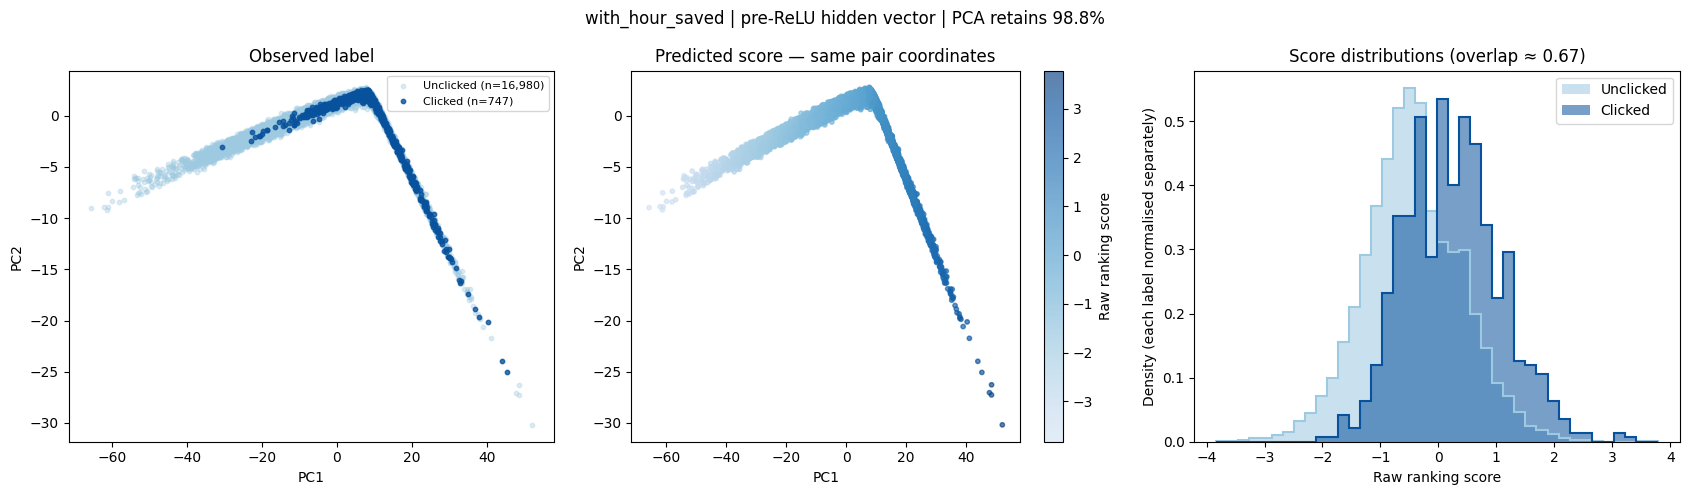

,model,label,n,mean_score,std_score,q25_score,median_score,q75_score,pca_retained_variance,histogram_overlap
0,with_hour_saved,unclicked,16980,-0.440374,0.841049,-0.975762,-0.470154,0.10752,0.98759,0.669897
1,with_hour_saved,clicked,747,0.242879,0.821112,-0.362080,0.210714,0.77277,0.98759,0.669897


In [14]:
rng=np.random.default_rng(SEED)
Ad=A["test"]
sample_g=np.sort(rng.choice(len(Ad["n"]),min(LATENT_IMPRESSIONS,len(Ad["n"])),replace=False))
pair_groups=np.repeat(sample_g,Ad["n"][sample_g])
pair_rows=np.concatenate([np.arange(Ad["start"][g],Ad["start"][g]+Ad["n"][g]) for g in sample_g])
if not len(pair_rows): raise ValueError("No test candidates for pair-hidden diagnostics")
sample_labels=Ad["label"][pair_rows]
if len(np.unique(sample_labels))!=2:
    raise ValueError("Sample must contain clicked and unclicked candidates; increase LATENT_IMPRESSIONS")
pd.DataFrame(dict(group=pair_groups,impression_id=Ad["impression_id"][pair_groups],
    row=pair_rows,label=sample_labels)).to_csv(OUT_DIR/"pair_hidden_sample.csv",index=False)

@torch.no_grad()
def pair_hidden_vectors(model):
    """Output of the final hidden Linear layer, BEFORE its ReLU activation."""
    model.eval()
    if not (isinstance(model.mlp[-4],nn.Linear) and isinstance(model.mlp[-3],nn.ReLU)
            and isinstance(model.mlp[-2],nn.Dropout) and isinstance(model.mlp[-1],nn.Linear)):
        raise ValueError("Expected final hidden Linear -> ReLU -> Dropout -> scoring Linear")
    hidden_parts,score_parts=[],[]
    for start in range(0,len(pair_rows),512):
        gs,rs=pair_groups[start:start+512],pair_rows[start:start+512]
        news=torch.as_tensor(Ad["news"][rs,None],device=device)
        cand=torch.as_tensor(Ad["cand_x"][rs,None,:],device=device)
        prof=torch.as_tensor(Ad["prof"][gs],device=device)
        user=torch.as_tensor(Ad["user_x"][gs],device=device)
        context=torch.as_tensor(Ad["ctx_x"][gs],device=device)
        blocks=model.blocks(news,cand,prof,user,context)
        hidden=model.mlp[:-3](torch.cat(list(blocks.values()),-1))  # final hidden Linear output, before ReLU
        scores=model.mlp[-3:](hidden).squeeze(-1)  # keep ReLU -> eval Dropout -> scoring Linear
        actual=model(news,torch.ones_like(news,dtype=torch.bool),cand,prof,user,context)
        if not torch.allclose(scores,actual,atol=1e-6,rtol=1e-5):
            raise AssertionError("Extracted hidden vector does not reconstruct the model score")
        hidden_parts.append(hidden[:,0].cpu().numpy())
        score_parts.append(scores[:,0].cpu().numpy())
    return np.concatenate(hidden_parts),np.concatenate(score_parts)

def latent_diagnostics(model,name):
    hidden,scores=pair_hidden_vectors(model)
    pca=PCA(n_components=2)
    xy=pca.fit_transform(hidden)
    retained=float(pca.explained_variance_ratio_.sum())
    np.savez(OUT_DIR/f"pair_hidden_{name}.npz",hidden=hidden,representation="final_hidden_linear_pre_relu",scores=scores,
        pca=xy,labels=sample_labels,groups=pair_groups,rows=pair_rows,
        pca_retained_variance=retained)
    BLUE_LIGHT="#9ecae1"
    BLUE_DARK="#08519c"
    fig,axes=plt.subplots(1,3,figsize=(17,5))
    # Same coordinates in both scatter plots; only the colouring changes.
    for label,color,alpha in ((0,BLUE_LIGHT,.35),(1,BLUE_DARK,.8)):
        mask=sample_labels==label
        axes[0].scatter(xy[mask,0],xy[mask,1],s=10,c=color,alpha=alpha,
            label=f"{'Clicked' if label else 'Unclicked'} (n={mask.sum():,})")
    axes[0].set(title="Observed label",xlabel="PC1",ylabel="PC2")
    axes[0].legend(fontsize=8)
    from matplotlib.colors import LinearSegmentedColormap
    palette=LinearSegmentedColormap.from_list("pair_score_blues",plt.cm.Blues(np.linspace(.18,.95,256)))
    dots=axes[1].scatter(xy[:,0],xy[:,1],c=scores,cmap=palette,s=10,alpha=.65)
    axes[1].set(title="Predicted score — same pair coordinates",xlabel="PC1",ylabel="PC2")
    axes[1].set_xlim(axes[0].get_xlim())
    axes[1].set_ylim(axes[0].get_ylim())
    fig.colorbar(dots,ax=axes[1],label="Raw ranking score")
    bins=np.histogram_bin_edges(scores,bins=40)
    histograms={}
    rows=[]
    for label,color in ((0,BLUE_LIGHT),(1,BLUE_DARK)):
        values=scores[sample_labels==label]
        histograms[label],_=np.histogram(values,bins=bins,density=True)
        axes[2].hist(values,bins=bins,density=True,color=color,alpha=.55,
            label="Clicked" if label else "Unclicked")
        axes[2].hist(values,bins=bins,density=True,histtype="step",color=color,linewidth=1.5)
        rows.append(dict(model=name,label="clicked" if label else "unclicked",n=len(values),
            mean_score=float(values.mean()),std_score=float(values.std()),
            q25_score=float(np.quantile(values,.25)),median_score=float(np.median(values)),
            q75_score=float(np.quantile(values,.75)),pca_retained_variance=retained))
    # Descriptive overlap coefficient, sensitive to binning; not a ranking metric.
    overlap=float(np.sum(np.minimum(histograms[0],histograms[1])*np.diff(bins)))
    axes[2].set(title=f"Score distributions (overlap ≈ {overlap:.2f})",
        xlabel="Raw ranking score",ylabel="Density (each label normalised separately)")
    axes[2].legend()
    fig.suptitle(f"{name} | pre-ReLU hidden vector | PCA retains {retained:.1%}")
    savefig(f"pair_hidden_{name}.png")
    table=pd.DataFrame(rows)
    table["histogram_overlap"]=overlap
    table.to_csv(OUT_DIR/f"pair_score_distribution_{name}.csv",index=False)
    return table

reference_latent=latent_diagnostics(reference,"with_hour_saved")
display(reference_latent)


## 6. Only new training: same MLP and seed, remove both hour coordinates
Retain every other selected feature, shared category table, optimiser, cold-user simulation and training budget from the saved configuration. Train this one ablation from scratch with the same seed; do not fine-tune the reference. The context projection disappears when both coordinates are removed, so the parameter count/head input changes as expected in a group-removal ablation.

Keep best validation nDCG@5 weights. Cache this one run using the reference weights hash, feature identity, configuration, hyperparameters and experiment-code revision. A completed match reloads without training. If editing training code manually, update `TRAINING_REVISION` to invalidate the cache. No source introspection or automatic training during evaluation.


In [15]:
NO_HOUR_CFG=make_config("saved_best_without_hour",REFERENCE_CFG["groups"],
    sorted(set(REFERENCE_CFG["drop"])|{"hour_sin","hour_cos"}))
assert active_features(NO_HOUR_CFG)["context"]==[]
for key in ("popularity","user","user_x_article"):
    assert active_features(NO_HOUR_CFG)[key]==active_features(REFERENCE_CFG)[key]
assert NO_HOUR_CFG["groups"]==REFERENCE_CFG["groups"]
def file_hash(path):
    h=hashlib.sha256()
    with open(path,"rb") as f:
        for chunk in iter(lambda:f.read(8*1024*1024),b""):h.update(chunk)
    return h.hexdigest()
TRAINING_REVISION="f32c0abdf868a10b"
identity=dict(reference_sha256=file_hash(REFERENCE_WEIGHTS),feature_id=feature_id,
    cfg=NO_HOUR_CFG,hparams=hp,cold_rate=COLD_SIM_RATE,training_revision=TRAINING_REVISION)
digest=hashlib.sha256(json.dumps(identity,sort_keys=True).encode()).hexdigest()[:16]
ABLATION_DIR=OUT_DIR/f"without_hour_seed{SEED}_{digest}"
ABLATION_DIR.mkdir(exist_ok=True)
weights=ABLATION_DIR/"best.pt"
complete=ABLATION_DIR/"complete.json"
if weights.is_file() and complete.is_file() and json.loads(complete.read_text())==identity:
    without_hour=build_model(NO_HOUR_CFG)
    without_hour.load_state_dict(torch.load(weights,map_location=device,weights_only=True))
    no_hour_history=pd.read_csv(ABLATION_DIR/"training_history.csv")
    print("Loaded completed without-hour model; no training.")
else:
    print(f"Training ONE model: without hour, seed {SEED}, at most {MAX_EPOCHS} epochs")
    without_hour,no_hour_history=train_model(NO_HOUR_CFG,epochs=MAX_EPOCHS,patience=PATIENCE,
        seed=SEED,cold_rate=COLD_SIM_RATE,verbose=True)
    torch.save({k:v.detach().cpu() for k,v in without_hour.state_dict().items()},weights)
    no_hour_history.to_csv(ABLATION_DIR/"training_history.csv",index=False)
    complete.write_text(json.dumps(identity,indent=2))
without_hour.eval()
best_row=no_hour_history.loc[no_hour_history[f"val_{SELECT_METRIC}"].idxmax()]
print("Best no-hour epoch:",int(best_row.epoch),"validation nDCG@5:",best_row["val_nDCG@5"])


Loaded completed without-hour model; no training.
Best no-hour epoch: 2 validation nDCG@5: 0.3416267898572251


## 7. Model-level comparison and two 24-hour tables (one joint representation)
Use the same full impression slates for both models. Preserve source MRR and cohort semantics. The test day reports a fixed hypothesis (remove hour features), not a new model/feature search. The comparison has one training seed; bootstrap intervals cover sampled impressions only.

Hours come from original timestamps aligned to prepared impression IDs, without timezone conversion; cyclic features include minutes. Empty hours have missing metrics. Display cohort composition with each hour. This measures time-of-day ranking, not publication freshness: MIND has no publication timestamps.

Hourly tables report model ranking metrics, not separate article/category spaces. All comparison curves use blue shades.


VAL hourly comparison


,hour,n_impressions,cold_user_share,with_hour_saved_nDCG@5,with_hour_saved_nDCG@10,with_hour_saved_MRR,with_hour_saved_AUC,without_hour_nDCG@5,without_hour_nDCG@10,without_hour_MRR,without_hour_AUC,delta_with_minus_without,ci_low,ci_high
0,0,167,0.023952,0.371491,0.409239,0.333209,0.695935,0.372072,0.401288,0.328568,0.694184,-0.000581,-0.018667,0.016590
1,1,176,0.034091,0.351012,0.411927,0.326572,0.758064,0.338523,0.404984,0.319123,0.744098,0.012489,-0.008514,0.034590
2,2,276,0.032609,0.322643,0.360772,0.292346,0.677429,0.320429,0.369440,0.291212,0.688530,0.002214,-0.011621,0.016481
3,3,487,0.020534,0.342102,0.402990,0.316990,0.709372,0.346833,0.407922,0.323186,0.711509,-0.004731,-0.017982,0.008610
4,4,953,0.026233,0.337312,0.393005,0.308127,0.718210,0.330681,0.393969,0.309285,0.717631,0.006631,-0.003684,0.017046
5,5,1598,0.033792,0.361617,0.422545,0.331486,0.717417,0.363472,0.425176,0.330310,0.717966,-0.001855,-0.009070,0.005439
6,6,2099,0.028585,0.388552,0.441847,0.355251,0.715647,0.383552,0.437230,0.351682,0.710584,0.005000,-0.001440,0.011530
7,7,2179,0.020652,0.359640,0.419822,0.331061,0.705428,0.352370,0.410940,0.323084,0.696122,0.007270,0.001286,0.013844
8,8,2503,0.023572,0.365791,0.426077,0.338184,0.680881,0.362189,0.421796,0.336189,0.676253,0.003603,-0.001640,0.009045
9,9,2440,0.027049,0.343103,0.404153,0.313364,0.676604,0.333261,0.395670,0.306586,0.670230,0.009842,0.004053,0.015758


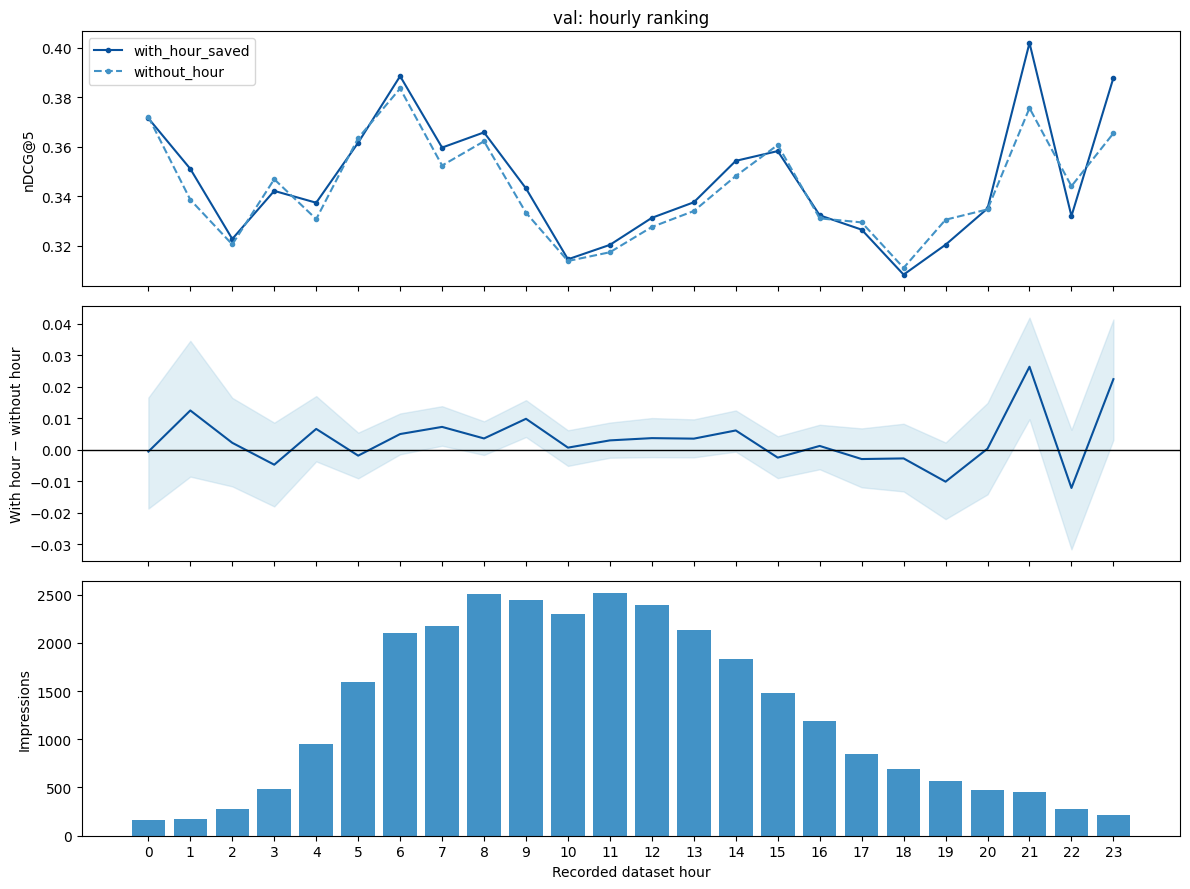

TEST hourly comparison


,hour,n_impressions,cold_user_share,with_hour_saved_nDCG@5,with_hour_saved_nDCG@10,with_hour_saved_MRR,with_hour_saved_AUC,without_hour_nDCG@5,without_hour_nDCG@10,without_hour_MRR,without_hour_AUC,delta_with_minus_without,ci_low,ci_high
0,0,529,0.043478,0.383687,0.439249,0.341691,0.661489,0.378965,0.438471,0.339333,0.670561,0.004722,-0.005856,0.016684
1,1,575,0.040000,0.371702,0.427585,0.331601,0.659193,0.367063,0.425638,0.326036,0.654927,0.004639,-0.004660,0.013810
2,2,980,0.019388,0.414033,0.474067,0.372046,0.687103,0.401588,0.462573,0.360360,0.675625,0.012445,0.003867,0.021130
3,3,1763,0.021554,0.407219,0.470786,0.373000,0.690410,0.384256,0.447236,0.346153,0.670681,0.022963,0.015614,0.029841
4,4,3094,0.025533,0.388053,0.449668,0.353495,0.680151,0.378886,0.443110,0.346341,0.678189,0.009168,0.004004,0.014900
5,5,4955,0.027447,0.393880,0.454228,0.362382,0.682883,0.388174,0.449523,0.355737,0.681389,0.005706,0.001602,0.009603
6,6,6112,0.031414,0.372447,0.436231,0.338948,0.683108,0.368785,0.434077,0.335921,0.681329,0.003662,0.000135,0.007544
7,7,6453,0.028204,0.362554,0.426151,0.330821,0.673629,0.361130,0.426004,0.330280,0.673725,0.001424,-0.002049,0.004859
8,8,6903,0.032305,0.364068,0.425822,0.329944,0.669503,0.362741,0.424664,0.328580,0.668844,0.001327,-0.002175,0.004491
9,9,6536,0.032436,0.344876,0.412069,0.312522,0.653288,0.350106,0.416532,0.316468,0.660668,-0.005230,-0.008620,-0.001868


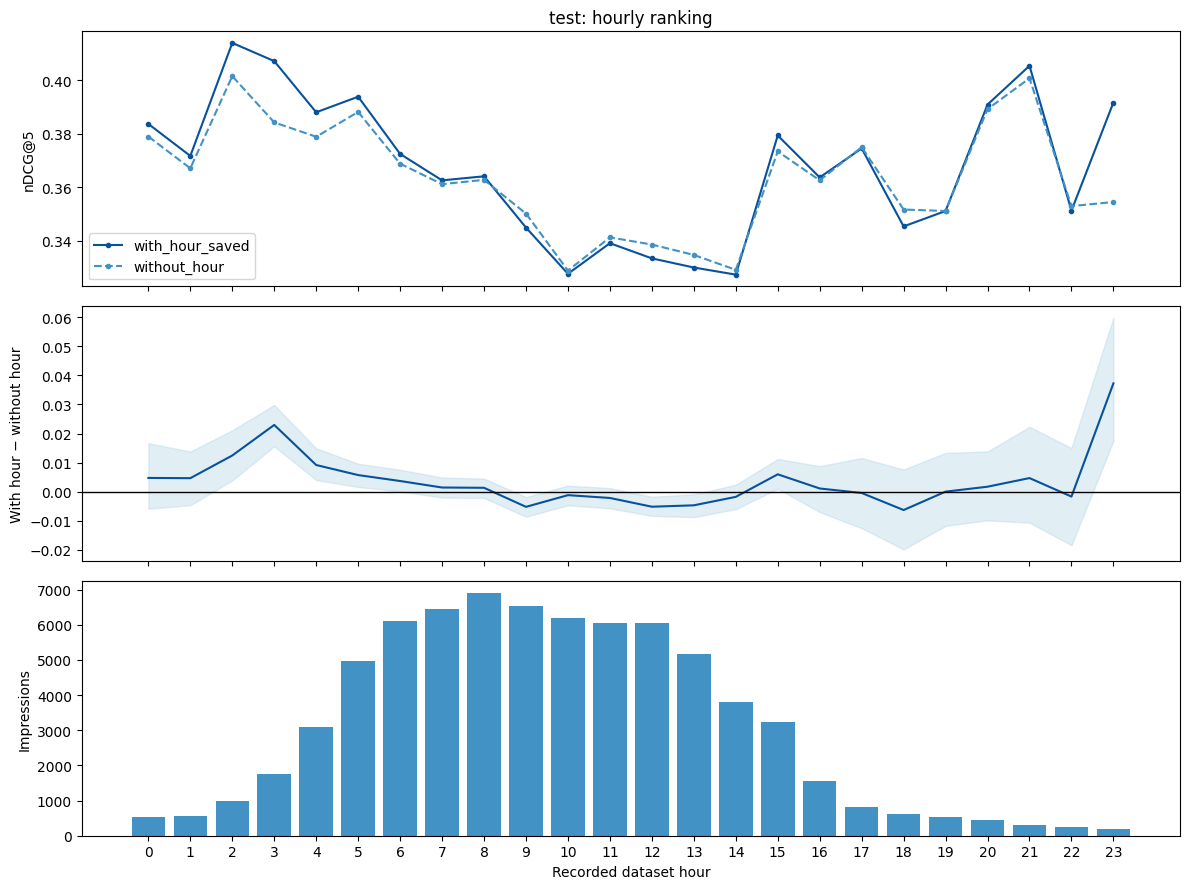

,split,model,slice,n_impressions,n_users,AUC,MRR,nDCG@5,nDCG@10,Recall@5,Recall@10
0,val,with_hour_saved,all,30270,20179,0.672316,0.317046,0.344972,0.405380,0.471818,0.644111
1,val,with_hour_saved,cold_user,772,476,0.584211,0.250682,0.264428,0.318851,0.381353,0.538133
2,val,with_hour_saved,sparse_user,3247,2657,0.608329,0.301738,0.317527,0.378027,0.454037,0.632831
3,val,with_hour_saved,warm_user,26251,17046,0.682821,0.320891,0.350735,0.411307,0.476678,0.648622
4,val,with_hour_saved,cold_article,22543,16161,0.664274,0.332246,0.359402,0.416779,0.498759,0.664660
5,val,without_hour,all,30270,20179,0.668590,0.313999,0.341627,0.401560,0.468353,0.638936
6,val,without_hour,cold_user,772,476,0.566682,0.239605,0.248983,0.308295,0.361889,0.532167
7,val,without_hour,sparse_user,3247,2657,0.604272,0.297883,0.314603,0.372411,0.452870,0.623135
8,val,without_hour,warm_user,26251,17046,0.679543,0.318180,0.347694,0.407908,0.473399,0.644030
9,val,without_hour,cold_article,22543,16161,0.660801,0.327617,0.353605,0.411480,0.491463,0.659172


In [16]:
def recorded_hours(split):
    """Hour bucket from original timestamps, aligned to prepared impression IDs.

    Cyclic features encode hour + minute/60; rounding their angle is not a
    valid way to assign the recorded hour bucket (especially near midnight).
    """
    ids=A[split]["impression_id"]
    impressions=data[split]["imp"].set_index("impression_id")
    if not impressions.index.is_unique:
        raise ValueError("Impression IDs must be unique before assigning hours")
    timestamp=pd.to_datetime(impressions.loc[ids,"time"],errors="raise")
    if timestamp.isna().any():
        raise ValueError("Missing impression timestamps in hourly evaluation")
    if len(timestamp)!=len(A[split]["n"]):
        raise ValueError("Timestamp rows do not match prepared impression order")
    return timestamp.dt.hour.to_numpy(dtype=np.int64)

def bootstrap_diff(diff):
    values=np.asarray(diff)
    if len(values)<2:return np.nan,np.nan
    rng=np.random.default_rng(SEED)
    means=[rng.choice(values,len(values),replace=True).mean() for _ in range(BOOTSTRAP_REPEATS)]
    return tuple(np.quantile(means,[.025,.975]))

models={"with_hour_saved":reference,"without_hour":without_hour}
metric_rows=[]
hourly={}
for split in ("val","test"):
    per={}
    for name,model in models.items():
        table,per[name]=evaluate(A[split],predict(model,A[split]))
        table.insert(0,"model",name)
        table.insert(0,"split",split)
        metric_rows.extend(table.to_dict("records"))
    hour=recorded_hours(split)
    rows=[]
    for h in range(24):
        mask=hour==h
        row=dict(hour=h,n_impressions=int(mask.sum()),
            cold_user_share=float((A[split]["hist_len"][mask]==0).mean()) if mask.any() else np.nan)
        for name in models:
            for metric in ("nDCG@5","nDCG@10","MRR","AUC"):
                row[name+"_"+metric]=per[name].loc[mask,metric].mean()
        difference=per["with_hour_saved"].loc[mask,"nDCG@5"]-per["without_hour"].loc[mask,"nDCG@5"]
        row["delta_with_minus_without"]=difference.mean()
        row["ci_low"],row["ci_high"]=bootstrap_diff(difference)
        rows.append(row)
    hourly[split]=pd.DataFrame(rows)
    hourly[split].to_csv(OUT_DIR/f"hourly_{split}.csv",index=False)
    print(split.upper(),"hourly comparison")
    display(hourly[split])
    fig,axes=plt.subplots(3,1,figsize=(12,9),sharex=True)
    for name,color,style in (("with_hour_saved","#08519c","-"),("without_hour","#4292c6","--")):
        axes[0].plot(range(24),hourly[split][name+"_nDCG@5"],marker=".",label=name,color=color,linestyle=style)
    axes[0].set(title=split+": hourly ranking",ylabel="nDCG@5")
    axes[0].legend()
    axes[1].plot(range(24),hourly[split].delta_with_minus_without,color="#08519c")
    axes[1].fill_between(range(24),hourly[split].ci_low,hourly[split].ci_high,alpha=.3,color="#9ecae1")
    axes[1].axhline(0,color="black",lw=1)
    axes[1].set(ylabel="With hour − without hour")
    axes[2].bar(range(24),hourly[split].n_impressions,color="#4292c6")
    axes[2].set(xlabel="Recorded dataset hour",ylabel="Impressions",xticks=range(24))
    savefig(f"hourly_{split}.png")
metrics=pd.DataFrame(metric_rows)
metrics.to_csv(OUT_DIR/"comparison_metrics.csv",index=False)
display(metrics)


## 8. Without-hour pair hidden plot and score-distribution comparison

Use the same sampled user–candidate pairs and the same two blue label colours. Each model has one final hidden Linear representation before ReLU. PCA is fitted independently per model: compare label/score patterns, not absolute PC coordinates across models. Score scales are model-specific. The overlap coefficient is a descriptive histogram quantity with fixed 40-bin construction, not a substitute for within-impression ranking metrics. There are no article/category-space tables or distance claims.

Re-run Section 5 and this section to replace the previous latent diagnostics using already loaded weights. Section 6's training identity is unchanged, so a saved without-hour model is still reused.


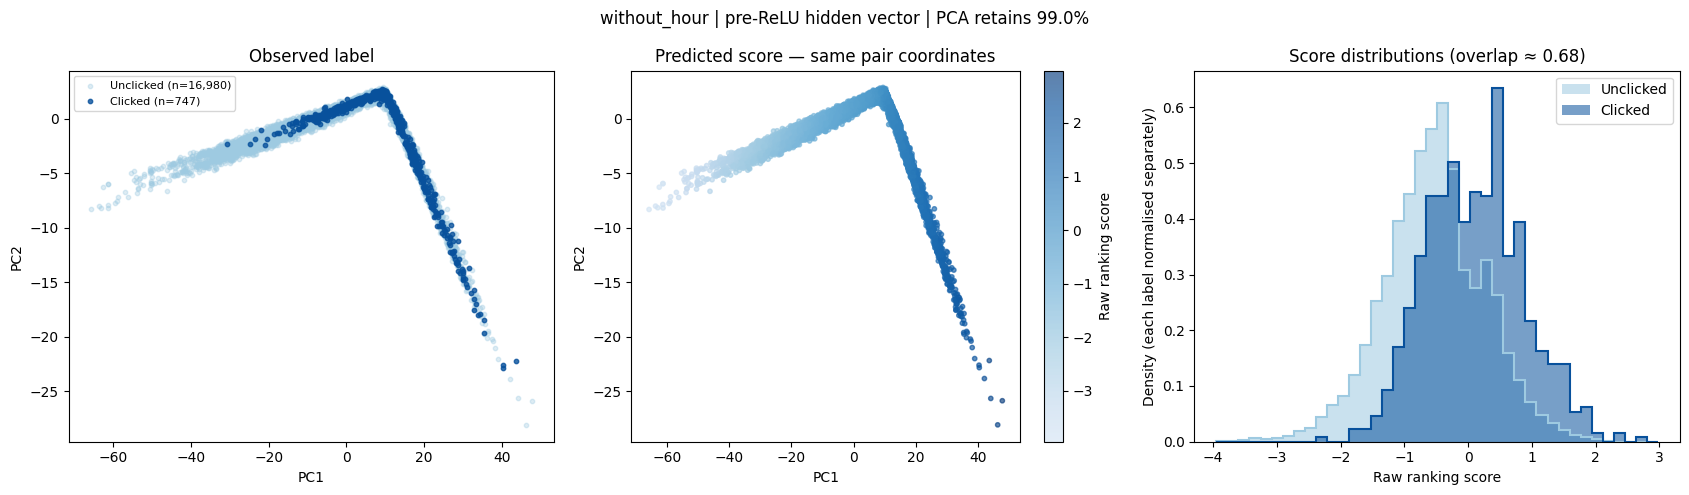

Score distributions — actual joint hidden representation, one per model


,model,label,n,mean_score,std_score,q25_score,median_score,q75_score,pca_retained_variance,histogram_overlap
0,with_hour_saved,unclicked,16980,-0.440374,0.841049,-0.975762,-0.470154,0.107520,0.987590,0.669897
1,with_hour_saved,clicked,747,0.242879,0.821112,-0.362080,0.210714,0.772770,0.987590,0.669897
2,without_hour,unclicked,16980,-0.530485,0.795410,-1.026404,-0.526378,-0.025464,0.990176,0.683614
3,without_hour,clicked,747,0.107790,0.759644,-0.458703,0.135005,0.608536,0.990176,0.683614


Finished. No extra fitting is performed by the hidden/score diagnostic cells.
Outputs: /content/drive/MyDrive/BT4222 - Group 12/runs/run_02/mlp/saved_best_hour_ablation


In [17]:
no_hour_latent=latent_diagnostics(without_hour,"without_hour")
latent_summary=pd.concat([reference_latent,no_hour_latent],ignore_index=True)
latent_summary.to_csv(OUT_DIR/"pair_score_distribution_comparison.csv",index=False)
print("Score distributions — actual joint hidden representation, one per model")
display(latent_summary)
(OUT_DIR/"pair_hidden_manifest.json").write_text(json.dumps(dict(reference=str(REFERENCE_WEIGHTS),
    reference_sha256=identity["reference_sha256"],seed=SEED,feature_id=feature_id,
    representation="final hidden Linear output before ReLU; score still uses ReLU then output Linear",
    sample="uniform test impressions; all candidates in each sampled slate",
    reference_config=REFERENCE_CFG,without_hour_config=NO_HOUR_CFG,
    cold_sim_rate=COLD_SIM_RATE,new_training_runs=1),indent=2))
print("Finished. No extra fitting is performed by the hidden/score diagnostic cells.")
print("Outputs:",OUT_DIR)
